# Loan Approval Prediction System
**Goal:** predict whether a loan application will be **Approved (1)** or **Rejected (0)**
from the applicant's details and financial information.

**Steps in this notebook**
1. Load the dataset
2. Clean and validate the data (preprocessing)
3. Exploratory Data Analysis (EDA)
4. Visualizations
5. Feature selection
6. Train and compare classification models
7. Evaluate the best model
8. Save the model and test a prediction

## 1. Import libraries and settings

In [1]:
import os
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from loan_common import (CATEGORICAL_FEATURES, MODEL_FEATURES, NUMERIC_FEATURES,
                         TARGET, VALID_CATEGORIES, VALID_RANGES, add_features)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

os.makedirs("images", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)

# Inside Jupyter we want to SEE the charts; when running as a plain .py
# script we only save them to the images/ folder.
IN_NOTEBOOK = "ipykernel" in sys.modules


def finish_plot(filename):
    """Save the current chart to images/ and show it (notebook only)."""
    plt.tight_layout()
    plt.savefig(os.path.join("images", filename), dpi=150, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close()

## 2. Load the dataset
If `data/loan_data.csv` does not exist yet, we create it with `generate_dataset.py`.

In [2]:
DATA_PATH = os.path.join("data", "loan_data.csv")
if not os.path.exists(DATA_PATH):
    from generate_dataset import generate
    generate().to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (2030, 11)


,ApplicantID,Gender,Age,MonthlyIncome,LoanAmount,CreditScore,EmploymentStatus,ExistingLoans,LoanTerm,PropertyArea,LoanApproved
0,1001,Female,25.0,29300.0,4755000,691.0,Self-Employed,1,240,Semi-Urban,0
1,1002,Male,45.0,16600.0,535000,672.0,Unemployed,1,120,Semi-Urban,1
2,1003,Female,23.0,52400.0,190000,592.0,Self-Employed,0,24,Semi-Urban,0
3,1004,Female,33.0,31700.0,300000,738.0,Employed,1,36,Rural,1
4,1005,Male,30.0,61600.0,2735000,799.0,Employed,0,180,Urban,1


In [3]:
# A quick health check of the raw data
print("--- Data types ---")
print(df.dtypes, "\n")
print("--- Missing values per column ---")
print(df.isnull().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())

--- Data types ---
ApplicantID           int64
Gender                  str
Age                 float64
MonthlyIncome       float64
LoanAmount            int64
CreditScore         float64
EmploymentStatus        str
ExistingLoans         int64
LoanTerm              int64
PropertyArea            str
LoanApproved          int64
dtype: object 

--- Missing values per column ---
ApplicantID          0
Gender               0
Age                 40
MonthlyIncome       60
LoanAmount           0
CreditScore         60
EmploymentStatus    30
ExistingLoans        0
LoanTerm             0
PropertyArea        21
LoanApproved         0
dtype: int64 

Duplicate rows: 30


## 3. Data preprocessing
We found **missing values** and **duplicate rows**. We fix them here and then
validate the data so no impossible values remain.

In [4]:
# 3.1 Remove duplicate rows
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows -> {len(df)} rows left")

# Every ApplicantID must be unique
assert df["ApplicantID"].is_unique, "Duplicate ApplicantIDs found!"

Removed 30 duplicate rows -> 2000 rows left


In [5]:
# 3.2 Handle missing values
#   numbers      -> fill with the MEDIAN (not hurt by extreme values)
#   categories   -> fill with the MOST FREQUENT value (the mode)
numeric_cols = ["Age", "MonthlyIncome", "LoanAmount", "CreditScore", "ExistingLoans", "LoanTerm"]
categorical_cols = ["Gender", "EmploymentStatus", "PropertyArea"]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values left:", int(df.isnull().sum().sum()))

Missing values left: 0


In [6]:
# 3.3 Data validation: values must be inside realistic ranges / allowed lists
problems = 0
for col, (low, high) in VALID_RANGES.items():
    bad = ~df[col].between(low, high)
    problems += int(bad.sum())
    print(f"{col:<14} allowed {low:>9,} - {high:>11,}   invalid rows: {int(bad.sum())}")
for col, allowed in VALID_CATEGORIES.items():
    bad = ~df[col].isin(allowed)
    problems += int(bad.sum())
    print(f"{col:<14} allowed {allowed}   invalid rows: {int(bad.sum())}")
assert set(df[TARGET].unique()) <= {0, 1}, "Target must be 0 or 1"
print("\nValidation finished, problems found:", problems)

# Whole numbers should be stored as integers again after filling
for col in ["Age", "MonthlyIncome", "CreditScore"]:
    df[col] = df[col].round().astype(int)

Age            allowed        18 -          70   invalid rows: 0
MonthlyIncome  allowed     1,000 -   1,000,000   invalid rows: 0
LoanAmount     allowed    10,000 -  50,000,000   invalid rows: 0
CreditScore    allowed       300 -         900   invalid rows: 0
ExistingLoans  allowed         0 -          10   invalid rows: 0
LoanTerm       allowed         6 -         360   invalid rows: 0
Gender         allowed ['Male', 'Female']   invalid rows: 0
EmploymentStatus allowed ['Employed', 'Self-Employed', 'Unemployed']   invalid rows: 0
PropertyArea   allowed ['Urban', 'Semi-Urban', 'Rural']   invalid rows: 0

Validation finished, problems found: 0


### 3.4 Feature engineering
We add one useful feature: **EMIToIncomeRatio** = (loan amount / loan term) / monthly income.
It shows how heavy the monthly instalment is compared with income.

In [7]:
df = add_features(df)
df.to_csv(os.path.join("data", "loan_data_cleaned.csv"), index=False)
df.head()

,ApplicantID,Gender,Age,MonthlyIncome,LoanAmount,CreditScore,EmploymentStatus,ExistingLoans,LoanTerm,PropertyArea,LoanApproved,EMIToIncomeRatio
0,1001,Female,25,29300,4755000,691,Self-Employed,1,240,Semi-Urban,0,0.676195
1,1002,Male,45,16600,535000,672,Unemployed,1,120,Semi-Urban,1,0.268574
2,1003,Female,23,52400,190000,592,Self-Employed,0,24,Semi-Urban,0,0.151081
3,1004,Female,33,31700,300000,738,Employed,1,36,Rural,1,0.262881
4,1005,Male,30,61600,2735000,799,Employed,0,180,Urban,1,0.246663


## 4. Exploratory Data Analysis (EDA)

In [8]:
print("Overall approval rate: {:.1%}".format(df[TARGET].mean()))
df.describe().T.round(2)

Overall approval rate: 58.0%


,count,mean,std,min,25%,50%,75%,max
ApplicantID,2000.0,2000.50,577.49,1001.00,1500.75,2000.50,2500.25,3000.0
Age,2000.0,35.97,9.30,21.00,29.00,36.00,42.00,65.0
MonthlyIncome,2000.0,43686.75,33977.95,5000.00,22000.00,35200.00,53825.00,400000.0
LoanAmount,2000.0,1278300.00,1997720.55,10000.00,268750.00,635000.00,1430000.00,23175000.0
CreditScore,2000.0,685.93,89.28,311.00,624.00,685.00,746.00,900.0
ExistingLoans,2000.0,1.01,1.08,0.00,0.00,1.00,2.00,6.0
LoanTerm,2000.0,94.79,86.29,12.00,36.00,60.00,120.00,360.0
LoanApproved,2000.0,0.58,0.49,0.00,0.00,1.00,1.00,1.0
EMIToIncomeRatio,2000.0,0.31,0.15,0.04,0.21,0.28,0.38,2.1


In [9]:
# Impact of INCOME: split applicants into 4 equal-sized income groups
df["IncomeGroup"] = pd.qcut(df["MonthlyIncome"], 4, labels=["Low", "Lower-Mid", "Upper-Mid", "High"])
print("Approval rate by income group:")
print(df.groupby("IncomeGroup", observed=True)[TARGET].mean().round(3), "\n")

# Relationship with CREDIT SCORE
df["CreditBand"] = pd.cut(df["CreditScore"], [299, 550, 650, 750, 900],
                          labels=["<=550", "551-650", "651-750", "751+"])
print("Approval rate by credit score band:")
print(df.groupby("CreditBand", observed=True)[TARGET].mean().round(3), "\n")

# Approval by EMPLOYMENT type
print("Approval rate by employment status:")
print(df.groupby("EmploymentStatus")[TARGET].mean().round(3), "\n")

# Approval by property area and gender
print("Approval rate by property area:")
print(df.groupby("PropertyArea")[TARGET].mean().round(3), "\n")
print("Approval rate by gender (should be similar, as gender is not used):")
print(df.groupby("Gender")[TARGET].mean().round(3))

Approval rate by income group:
IncomeGroup
Low          0.327
Lower-Mid    0.562
Upper-Mid    0.663
High         0.772
Name: LoanApproved, dtype: float64 

Approval rate by credit score band:
CreditBand
<=550      0.008
551-650    0.300
651-750    0.660
751+       0.923
Name: LoanApproved, dtype: float64 

Approval rate by employment status:
EmploymentStatus
Employed         0.635
Self-Employed    0.597
Unemployed       0.106
Name: LoanApproved, dtype: float64 

Approval rate by property area:
PropertyArea
Rural         0.563
Semi-Urban    0.566
Urban         0.603
Name: LoanApproved, dtype: float64 

Approval rate by gender (should be similar, as gender is not used):
Gender
Female    0.564
Male      0.590
Name: LoanApproved, dtype: float64


In [10]:
# Average values of approved vs rejected applicants
df.groupby(TARGET)[["Age", "MonthlyIncome", "LoanAmount", "CreditScore",
                    "ExistingLoans", "EMIToIncomeRatio"]].mean().round(2)

,Age,MonthlyIncome,LoanAmount,CreditScore,ExistingLoans,EMIToIncomeRatio
LoanApproved,,,,,,
0,35.49,32255.77,1033513.67,626.74,1.46,0.34
1,36.33,51981.36,1455923.21,728.88,0.68,0.29


## 5. Visualizations
### 5.1 Bar chart - loan approvals by employment status

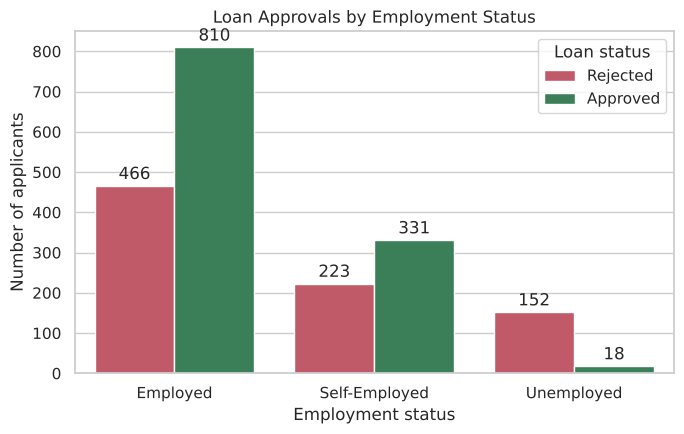

In [11]:
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(data=df, x="EmploymentStatus", hue=TARGET,
                   order=["Employed", "Self-Employed", "Unemployed"],
                   palette={0: "#d1495b", 1: "#2e8b57"})
ax.legend(title="Loan status", labels=["Rejected", "Approved"])
for container in ax.containers:
    ax.bar_label(container, padding=2)
plt.title("Loan Approvals by Employment Status")
plt.xlabel("Employment status")
plt.ylabel("Number of applicants")
finish_plot("01_approval_by_employment.png")

### 5.2 Correlation heatmap of numerical features

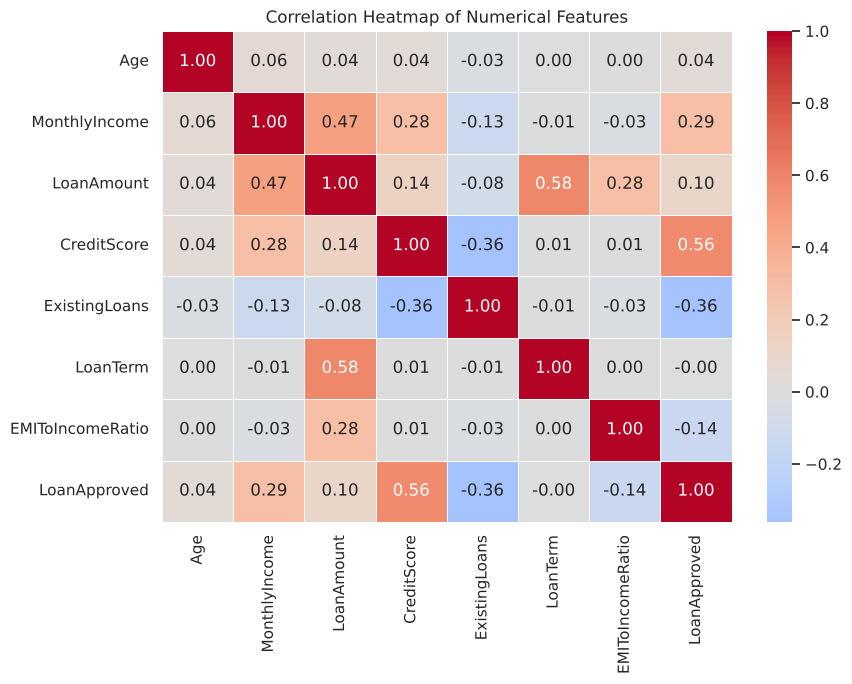

In [12]:
corr_cols = ["Age", "MonthlyIncome", "LoanAmount", "CreditScore",
             "ExistingLoans", "LoanTerm", "EMIToIncomeRatio", TARGET]
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
finish_plot("02_correlation_heatmap.png")

### 5.3 Scatter plot - income vs loan amount

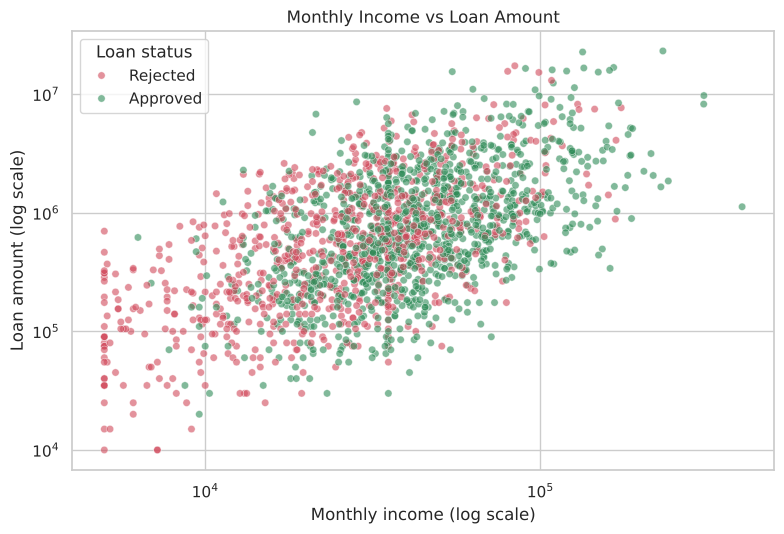

In [13]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=df, x="MonthlyIncome", y="LoanAmount", hue=df[TARGET].map({0: "Rejected", 1: "Approved"}),
                palette={"Rejected": "#d1495b", "Approved": "#2e8b57"}, alpha=0.6, s=28)
plt.xscale("log")
plt.yscale("log")        # log scales spread out the many small values
plt.title("Monthly Income vs Loan Amount")
plt.xlabel("Monthly income (log scale)")
plt.ylabel("Loan amount (log scale)")
plt.legend(title="Loan status")
finish_plot("03_income_vs_loan_amount.png")

### 5.4 Pie chart - approved vs rejected

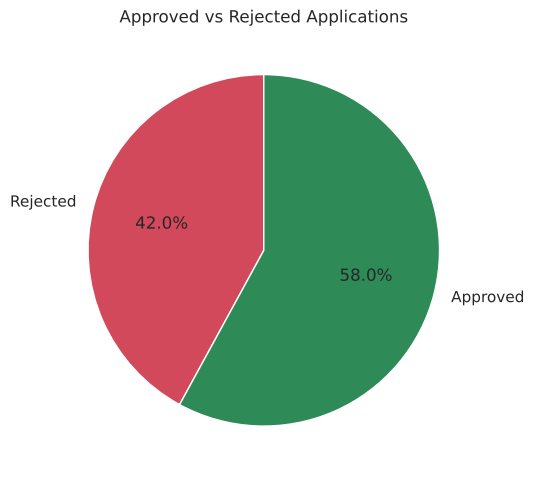

In [14]:
counts = df[TARGET].value_counts().sort_index()
plt.figure(figsize=(5.5, 5.5))
plt.pie(counts, labels=["Rejected", "Approved"], autopct="%1.1f%%", startangle=90,
        colors=["#d1495b", "#2e8b57"], wedgeprops={"edgecolor": "white"})
plt.title("Approved vs Rejected Applications")
finish_plot("04_approval_pie.png")

### 5.5 Extra charts - credit score and income vs approval

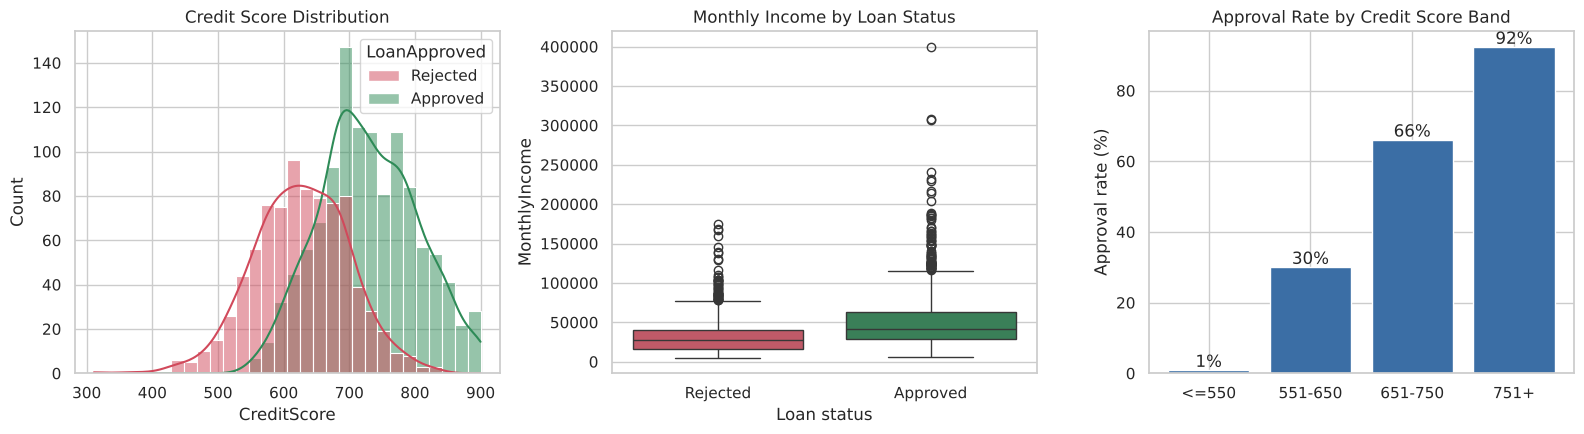

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(data=df, x="CreditScore", hue=df[TARGET].map({0: "Rejected", 1: "Approved"}),
             palette={"Rejected": "#d1495b", "Approved": "#2e8b57"}, bins=30, kde=True, ax=axes[0])
axes[0].set_title("Credit Score Distribution")

sns.boxplot(data=df, x=df[TARGET].map({0: "Rejected", 1: "Approved"}), y="MonthlyIncome",
            order=["Rejected", "Approved"], palette=["#d1495b", "#2e8b57"], ax=axes[1])
axes[1].set_title("Monthly Income by Loan Status")
axes[1].set_xlabel("Loan status")

rate = df.groupby("CreditBand", observed=True)[TARGET].mean() * 100
axes[2].bar(rate.index.astype(str), rate.values, color="#3b6ea5")
axes[2].set_title("Approval Rate by Credit Score Band")
axes[2].set_ylabel("Approval rate (%)")
for i, v in enumerate(rate.values):
    axes[2].text(i, v + 1, f"{v:.0f}%", ha="center")
finish_plot("05_credit_income_vs_approval.png")

## 6. Feature selection
We train on the columns below. **ApplicantID** is only a label, and **Gender** is left out
on purpose so the decision is not based on gender.

In [16]:
X = df[MODEL_FEATURES]
y = df[TARGET]
print("Features used:", MODEL_FEATURES)

Features used: ['Age', 'MonthlyIncome', 'LoanAmount', 'CreditScore', 'ExistingLoans', 'LoanTerm', 'EMIToIncomeRatio', 'EmploymentStatus', 'PropertyArea']


## 7. Train and compare classification models
* **Train/test split:** 80% to learn from, 20% to test on (stratified keeps the same approval ratio in both).
* **Preprocessing pipeline:** fill gaps, scale numbers, one-hot encode categories.
  Putting this *inside* the pipeline means the same steps run automatically on new applicants.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC_FEATURES),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL_FEATURES),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=3,
                                            random_state=RANDOM_STATE, n_jobs=-1),
}

Training rows: 1600 | Testing rows: 400


In [18]:
results, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1").mean()
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "CV F1 (5-fold)": cv,
    })
    fitted[name] = pipe

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1-Score,CV F1 (5-fold)
Model,,,,,
Logistic Regression,0.825,0.832,0.875,0.853,0.820
Decision Tree,0.808,0.835,0.832,0.834,0.798
Random Forest,0.832,0.834,0.888,0.860,0.818


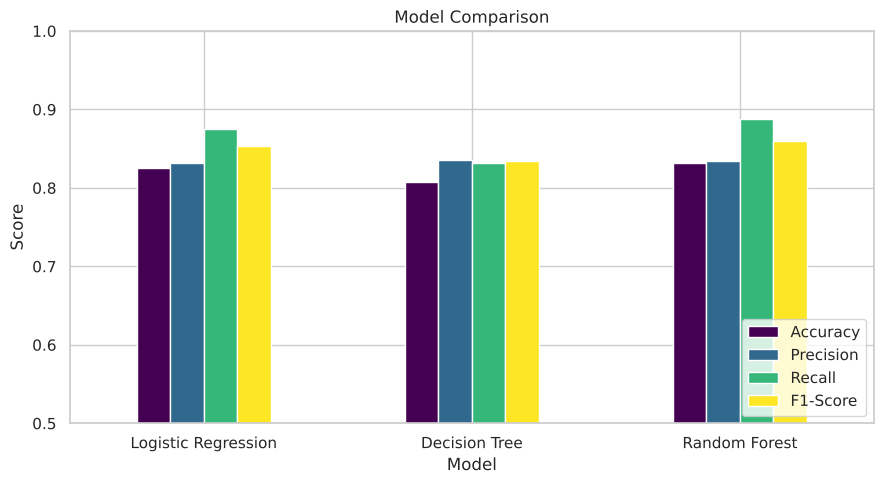

In [19]:
# Bar chart comparing the models
results_df[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(
    kind="bar", figsize=(9, 5), colormap="viridis", rot=0)
plt.title("Model Comparison")
plt.ylim(0.5, 1.0)
plt.ylabel("Score")
plt.legend(loc="lower right")
finish_plot("06_model_comparison.png")

## 8. Evaluate the best model
We pick the model with the best **F1-Score** (a balance of precision and recall).

In [20]:
best_name = results_df["F1-Score"].idxmax()
best_model = fitted[best_name]
print("Best model:", best_name, "\n")

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Rejected", "Approved"]))

Best model: Random Forest 

              precision    recall  f1-score   support

    Rejected       0.83      0.76      0.79       168
    Approved       0.83      0.89      0.86       232

    accuracy                           0.83       400
   macro avg       0.83      0.82      0.83       400
weighted avg       0.83      0.83      0.83       400



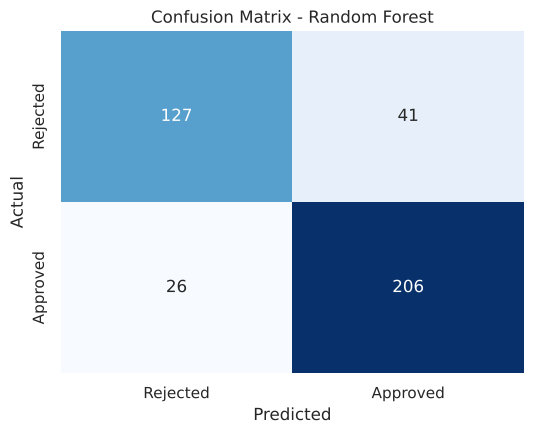

Correct rejections: 127 | Wrongly approved: 41 | Wrongly rejected: 26 | Correct approvals: 206


In [21]:
# Confusion matrix of the best model
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Rejected", "Approved"], yticklabels=["Rejected", "Approved"])
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
finish_plot("07_confusion_matrix.png")

tn, fp, fn, tp = cm.ravel()
print(f"Correct rejections: {tn} | Wrongly approved: {fp} | Wrongly rejected: {fn} | Correct approvals: {tp}")

### Feature importance (Random Forest)
Shows which details influence the decision the most.

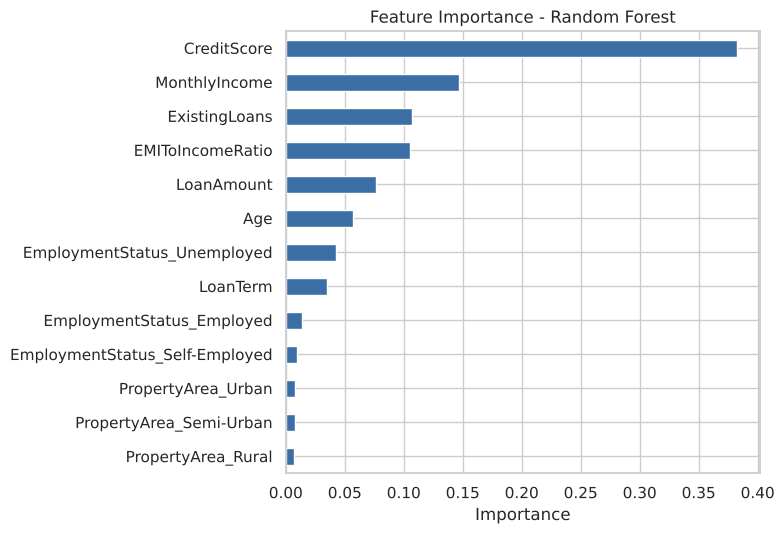

CreditScore                       0.383
MonthlyIncome                     0.147
ExistingLoans                     0.107
EMIToIncomeRatio                  0.106
LoanAmount                        0.077
Age                               0.057
EmploymentStatus_Unemployed       0.042
LoanTerm                          0.035
EmploymentStatus_Employed         0.014
EmploymentStatus_Self-Employed    0.010
PropertyArea_Urban                0.008
PropertyArea_Semi-Urban           0.008
PropertyArea_Rural                0.007
dtype: float64

In [22]:
rf_pipe = fitted["Random Forest"]
feature_names = rf_pipe.named_steps["prep"].get_feature_names_out()
feature_names = [n.split("__")[1] for n in feature_names]
importance = pd.Series(rf_pipe.named_steps["model"].feature_importances_,
                       index=feature_names).sort_values()

plt.figure(figsize=(8, 5.5))
importance.plot(kind="barh", color="#3b6ea5")
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
finish_plot("08_feature_importance.png")
importance.sort_values(ascending=False).round(3)

## 9. Save the model and try a prediction
The saved file contains the *whole pipeline*, so `predict_cli.py` can load it and
predict directly from raw applicant details.

In [23]:
joblib.dump(best_model, os.path.join("models", "loan_model.joblib"))
print("Model saved to models/loan_model.joblib")

new_applicant = pd.DataFrame([{
    "Age": 32, "MonthlyIncome": 55000, "LoanAmount": 900000, "CreditScore": 740,
    "ExistingLoans": 1, "LoanTerm": 60, "EmploymentStatus": "Employed", "PropertyArea": "Urban",
}])
new_applicant = add_features(new_applicant)
pred = best_model.predict(new_applicant[MODEL_FEATURES])[0]
prob = best_model.predict_proba(new_applicant[MODEL_FEATURES])[0][1]
print(f"Prediction: {'APPROVED' if pred == 1 else 'REJECTED'}  (approval probability {prob:.1%})")

Model saved to models/loan_model.joblib
Prediction: APPROVED  (approval probability 87.5%)


## 10. Key insights
* Credit score, employment status, income and the EMI-to-income ratio are the strongest drivers of approval.
* Unemployed applicants are rarely approved; employed and self-employed applicants are approved at similar rates.
* Applicants whose instalment is a big share of their income, or who already hold several loans, are rejected more often.
* Gender is not used by the model, and approval rates for men and women are almost the same.